In [ ]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import zipfile
import os

zip_path = "/content/archive (5).zip"
extract_path = "/content/customer_support_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP file extracted successfully!")

ZIP file extracted successfully!


In [ ]:
os.listdir(extract_path)

['dataset-tickets-multi-lang-4-20k.csv',
 'dataset-tickets-german_normalized.csv',
 'aa_dataset-tickets-multi-lang-5-2-50-version.csv',
 'dataset-tickets-german_normalized_50_5_2.csv',
 'dataset-tickets-multi-lang3-4k.csv']

In [ ]:
file_path = "/content/customer_support_data/aa_dataset-tickets-multi-lang-5-2-50-version.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 28587
Number of columns: 16


In [ ]:
df.head()

,subject,body,answer,type,queue,priority,language,version,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8
0,Wesentlicher Sicherheitsvorfall,"Sehr geehrtes Support-Team,\n\nich möchte eine...",Vielen Dank für die Meldung des kritischen Sic...,Incident,Technical Support,high,de,51,Security,Outage,Disruption,Data Breach,NaN,NaN,NaN,NaN
1,Account Disruption,"Dear Customer Support Team,\n\nI am writing to...","Thank you for reaching out, <name>. We are awa...",Incident,Technical Support,high,en,51,Account,Disruption,Outage,IT,Tech Support,NaN,NaN,NaN
2,Query About Smart Home System Integration Feat...,"Dear Customer Support Team,\n\nI hope this mes...",Thank you for your inquiry. Our products suppo...,Request,Returns and Exchanges,medium,en,51,Product,Feature,Tech Support,NaN,NaN,NaN,NaN,NaN
3,Inquiry Regarding Invoice Details,"Dear Customer Support Team,\n\nI hope this mes...",We appreciate you reaching out with your billi...,Request,Billing and Payments,low,en,51,Billing,Payment,Account,Documentation,Feedback,NaN,NaN,NaN
4,Question About Marketing Agency Software Compa...,"Dear Support Team,\n\nI hope this message reac...",Thank you for your inquiry. Our product suppor...,Problem,Sales and Pre-Sales,medium,en,51,Product,Feature,Feedback,Tech Support,NaN,NaN,NaN,NaN


In [ ]:
print(df.columns.tolist())

['subject', 'body', 'answer', 'type', 'queue', 'priority', 'language', 'version', 'tag_1', 'tag_2', 'tag_3', 'tag_4', 'tag_5', 'tag_6', 'tag_7', 'tag_8']


In [ ]:
for i, col in enumerate(df.columns):
    print(i, repr(col))

0 'subject'
1 'body'
2 'answer'
3 'type'
4 'queue'
5 'priority'
6 'language'
7 'version'
8 'tag_1'
9 'tag_2'
10 'tag_3'
11 'tag_4'
12 'tag_5'
13 'tag_6'
14 'tag_7'
15 'tag_8'


In [ ]:
print(df.isnull().sum())

subject      3838
body            0
answer          7
type            0
queue           0
priority        0
language        0
version         0
tag_1           0
tag_2          13
tag_3         136
tag_4        3058
tag_5       14042
tag_6       22713
tag_7       26547
tag_8       28022
dtype: int64


In [ ]:
print("Queue categories:")
print(df["queue"].value_counts())

print("\nPriority categories:")
print(df["priority"].value_counts())

Queue categories:
queue
Technical Support                  8362
Product Support                    5252
Customer Service                   4268
IT Support                         3433
Billing and Payments               2788
Returns and Exchanges              1437
Service Outages and Maintenance    1148
Sales and Pre-Sales                 918
Human Resources                     576
General Inquiry                     405
Name: count, dtype: int64

Priority categories:
priority
medium    11515
high      11178
low        5894
Name: count, dtype: int64


In [ ]:
print(df.isnull().sum())

subject      3838
body            0
answer          7
type            0
queue           0
priority        0
language        0
version         0
tag_1           0
tag_2          13
tag_3         136
tag_4        3058
tag_5       14042
tag_6       22713
tag_7       26547
tag_8       28022
dtype: int64


In [ ]:
print(df["queue"].value_counts())

queue
Technical Support                  8362
Product Support                    5252
Customer Service                   4268
IT Support                         3433
Billing and Payments               2788
Returns and Exchanges              1437
Service Outages and Maintenance    1148
Sales and Pre-Sales                 918
Human Resources                     576
General Inquiry                     405
Name: count, dtype: int64


In [ ]:
print(df["priority"].value_counts())

priority
medium    11515
high      11178
low        5894
Name: count, dtype: int64


In [ ]:
print(df["language"].value_counts())

language
en    16338
de    12249
Name: count, dtype: int64


In [ ]:
# Keep only English tickets
df_en = df[df["language"] == "en"].copy()

print("English dataset shape:", df_en.shape)

English dataset shape: (16338, 16)


In [ ]:
df_en[["subject", "body", "queue", "priority"]].head()

,subject,body,queue,priority
1,Account Disruption,"Dear Customer Support Team,\n\nI am writing to...",Technical Support,high
2,Query About Smart Home System Integration Feat...,"Dear Customer Support Team,\n\nI hope this mes...",Returns and Exchanges,medium
3,Inquiry Regarding Invoice Details,"Dear Customer Support Team,\n\nI hope this mes...",Billing and Payments,low
4,Question About Marketing Agency Software Compa...,"Dear Support Team,\n\nI hope this message reac...",Sales and Pre-Sales,medium
5,Feature Query,"Dear Customer Support,\n\nI hope this message ...",Technical Support,high


In [ ]:
# Replace missing subjects with empty text
df_en["subject"] = df_en["subject"].fillna("")

# Combine subject and body
df_en["text"] = df_en["subject"] + " " + df_en["body"]

print(df_en[["subject", "body", "text"]].head())

                                             subject  \
1                                 Account Disruption   
2  Query About Smart Home System Integration Feat...   
3                  Inquiry Regarding Invoice Details   
4  Question About Marketing Agency Software Compa...   
5                                      Feature Query   

                                                body  \
1  Dear Customer Support Team,\n\nI am writing to...   
2  Dear Customer Support Team,\n\nI hope this mes...   
3  Dear Customer Support Team,\n\nI hope this mes...   
4  Dear Support Team,\n\nI hope this message reac...   
5  Dear Customer Support,\n\nI hope this message ...   

                                                text  
1  Account Disruption Dear Customer Support Team,...  
2  Query About Smart Home System Integration Feat...  
3  Inquiry Regarding Invoice Details Dear Custome...  
4  Question About Marketing Agency Software Compa...  
5  Feature Query Dear Customer Support,\n\nI hope..

In [ ]:
print("Total English tickets:", len(df_en))
print("Missing text:", df_en["text"].isnull().sum())
print("Missing queue:", df_en["queue"].isnull().sum())
print("Missing priority:", df_en["priority"].isnull().sum())

Total English tickets: 16338
Missing text: 0
Missing queue: 0
Missing priority: 0


In [ ]:
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download required NLP resources
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

# English stopwords
stop_words = set(stopwords.words("english"))

# Lemmatizer
lemmatizer = WordNetLemmatizer()

print("NLP libraries and resources are ready!")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


NLP libraries and resources are ready!


[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


In [ ]:
def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Tokenize
    words = text.split()

    # Remove stopwords and lemmatize
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    # Join words back into text
    return " ".join(words)


print("Preprocessing function created successfully!")

Preprocessing function created successfully!


In [ ]:
sample_text = df_en["text"].iloc[0]

print("BEFORE PREPROCESSING:")
print(sample_text)

print("\nAFTER PREPROCESSING:")
print(preprocess_text(sample_text))

BEFORE PREPROCESSING:
Account Disruption Dear Customer Support Team,\n\nI am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. This outage is blocking access to account settings, leading to substantial inconvenience. I have attempted to log in multiple times using different browsers and devices, but the issue persists.\n\nCould you please provide an update on the outage status and an estimated time for resolution? Also, are there any alternative ways to access and manage my account during this downtime?

AFTER PREPROCESSING:
account disruption dear customer support team n ni writing report significant problem centralized account management portal currently appears offline outage blocking access account setting leading substantial inconvenience attempted log multiple time using different browser device issue persists n ncould please provide update outage status estimated time resolution also alternative way acc

In [ ]:
def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()

    # Replace literal newline characters
    text = text.replace("\\n", " ")

    # Remove actual newline characters
    text = text.replace("\n", " ")

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Tokenize
    words = text.split()

    # Remove stopwords and lemmatize
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    # Join words back into text
    return " ".join(words)


print("Improved preprocessing function created successfully!")

Improved preprocessing function created successfully!


In [ ]:
sample_text = df_en["text"].iloc[0]

print("BEFORE PREPROCESSING:")
print(sample_text)

print("\nAFTER PREPROCESSING:")
print(preprocess_text(sample_text))

BEFORE PREPROCESSING:
Account Disruption Dear Customer Support Team,\n\nI am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. This outage is blocking access to account settings, leading to substantial inconvenience. I have attempted to log in multiple times using different browsers and devices, but the issue persists.\n\nCould you please provide an update on the outage status and an estimated time for resolution? Also, are there any alternative ways to access and manage my account during this downtime?

AFTER PREPROCESSING:
account disruption dear customer support team writing report significant problem centralized account management portal currently appears offline outage blocking access account setting leading substantial inconvenience attempted log multiple time using different browser device issue persists could please provide update outage status estimated time resolution also alternative way access mana

In [ ]:
df_en["clean_text"] = df_en["text"].apply(preprocess_text)

print("Preprocessing completed successfully!")
print("Total tickets:", len(df_en))

Preprocessing completed successfully!
Total tickets: 16338


In [ ]:
df_en[["text", "clean_text"]].head(3)

,text,clean_text
1,"Account Disruption Dear Customer Support Team,...",account disruption dear customer support team ...
2,Query About Smart Home System Integration Feat...,query smart home system integration feature de...
3,Inquiry Regarding Invoice Details Dear Custome...,inquiry regarding invoice detail dear customer...


In [ ]:
import matplotlib.pyplot as plt

queue_counts = df_en["queue"].value_counts()

print(queue_counts)

queue
Technical Support                  4737
Product Support                    3073
Customer Service                   2410
IT Support                         1942
Billing and Payments               1595
Returns and Exchanges               820
Service Outages and Maintenance     664
Sales and Pre-Sales                 513
Human Resources                     348
General Inquiry                     236
Name: count, dtype: int64


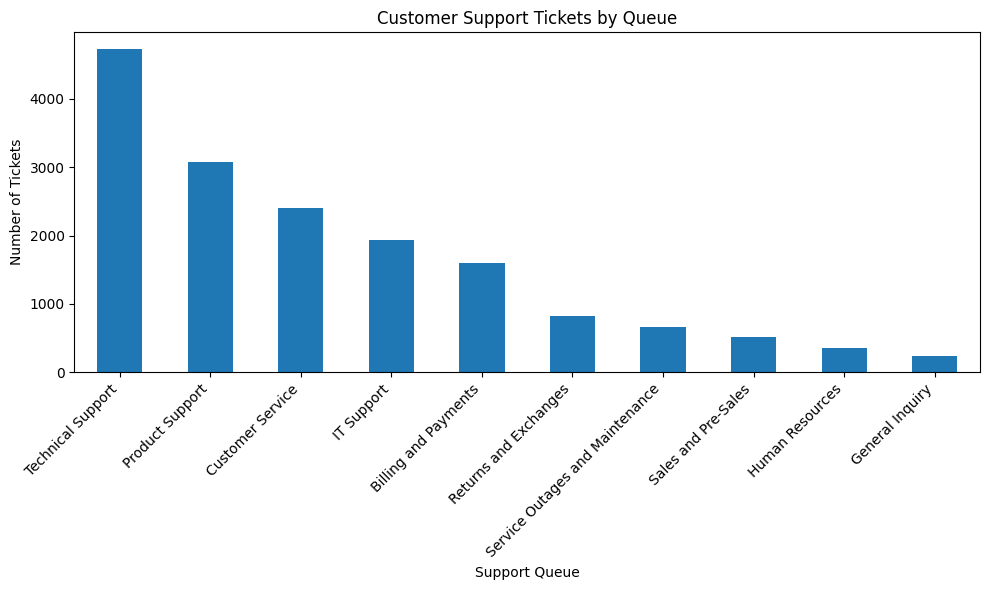

In [ ]:
plt.figure(figsize=(10, 6))

queue_counts.plot(kind="bar")

plt.title("Customer Support Tickets by Queue")
plt.xlabel("Support Queue")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
priority_counts = df_en["priority"].value_counts()

print(priority_counts)

priority
medium    6618
high      6346
low       3374
Name: count, dtype: int64


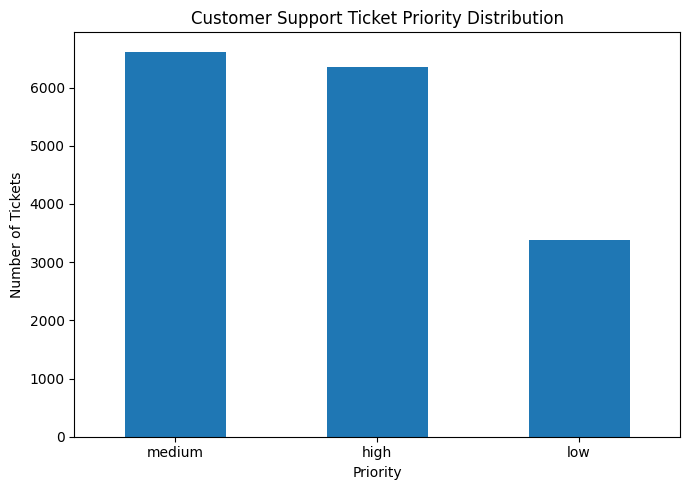

In [ ]:
plt.figure(figsize=(7, 5))

priority_counts.plot(kind="bar")

plt.title("Customer Support Ticket Priority Distribution")
plt.xlabel("Priority")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
df_en["text_length"] = df_en["clean_text"].apply(lambda x: len(x.split()))

print(df_en["text_length"].describe())

count    16338.000000
mean        37.917309
std         16.243072
min          2.000000
25%         24.000000
50%         39.000000
75%         52.000000
max        105.000000
Name: text_length, dtype: float64


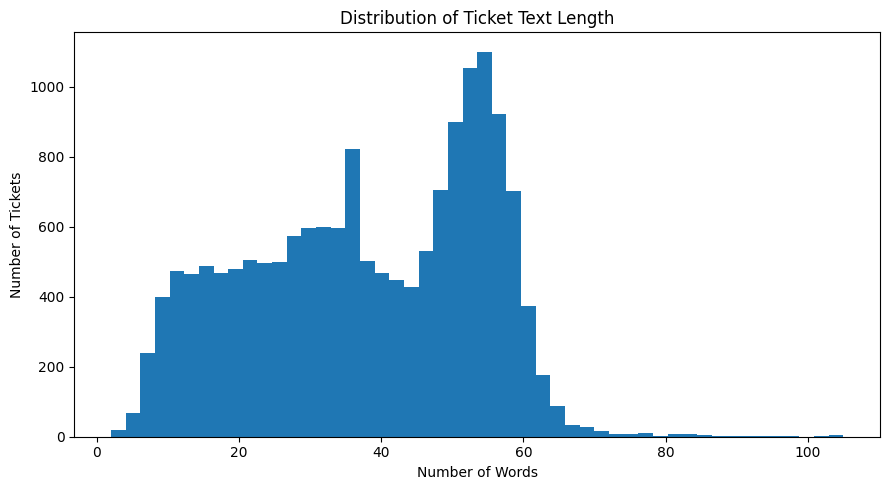

In [ ]:
plt.figure(figsize=(9, 5))

plt.hist(df_en["text_length"], bins=50)

plt.title("Distribution of Ticket Text Length")
plt.xlabel("Number of Words")
plt.ylabel("Number of Tickets")

plt.tight_layout()
plt.show()

In [ ]:
from collections import Counter

all_words = " ".join(df_en["clean_text"]).split()

word_counts = Counter(all_words)

print("Top 20 most frequent words:")
print(word_counts.most_common(20))

Top 20 most frequent words:
[('data', 13928), ('issue', 11617), ('support', 8589), ('would', 8291), ('system', 7379), ('problem', 7219), ('could', 6884), ('assistance', 6675), ('customer', 6126), ('security', 6025), ('software', 5931), ('information', 5454), ('provide', 5341), ('integration', 5286), ('appreciate', 5230), ('analytics', 5064), ('investment', 4969), ('due', 4800), ('update', 4766), ('digital', 4722)]


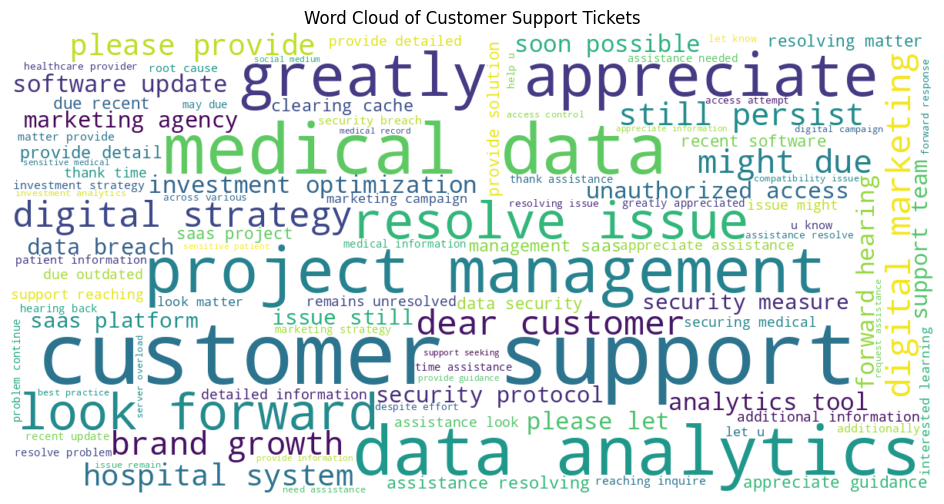

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

text_data = " ".join(df_en["clean_text"])

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100
).generate(text_data)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Customer Support Tickets")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X = df_en["clean_text"]
y = df_en["queue"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Total samples:", len(X_train) + len(X_test))

Training samples: 13070
Testing samples: 3268
Total samples: 16338


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF feature extraction completed!")
print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

TF-IDF feature extraction completed!
Training feature shape: (13070, 5000)
Testing feature shape: (3268, 5000)


In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

y_pred_nb = nb_model.predict(X_test_tfidf)

nb_accuracy = accuracy_score(y_test, y_pred_nb)

print("Naïve Bayes Accuracy:", nb_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

Naïve Bayes Accuracy: 0.40850673194614445

Classification Report:
                                 precision    recall  f1-score   support

           Billing and Payments       0.90      0.61      0.73       319
               Customer Service       0.26      0.42      0.32       482
                General Inquiry       0.00      0.00      0.00        47
                Human Resources       0.00      0.00      0.00        70
                     IT Support       0.62      0.04      0.07       388
                Product Support       0.38      0.30      0.33       615
          Returns and Exchanges       1.00      0.05      0.10       164
            Sales and Pre-Sales       0.00      0.00      0.00       103
Service Outages and Maintenance       0.94      0.26      0.40       133
              Technical Support       0.41      0.73      0.52       947

                       accuracy                           0.41      3268
                      macro avg       0.45      0.24    

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_model.predict(X_test_tfidf)

lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", lr_accuracy)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    zero_division=0
))

Logistic Regression Accuracy: 0.4920440636474908

Classification Report:
                                 precision    recall  f1-score   support

           Billing and Payments       0.85      0.70      0.77       319
               Customer Service       0.40      0.37      0.38       482
                General Inquiry       1.00      0.04      0.08        47
                Human Resources       1.00      0.13      0.23        70
                     IT Support       0.51      0.24      0.33       388
                Product Support       0.42      0.46      0.44       615
          Returns and Exchanges       0.78      0.13      0.22       164
            Sales and Pre-Sales       0.67      0.12      0.20       103
Service Outages and Maintenance       0.80      0.49      0.61       133
              Technical Support       0.46      0.77      0.57       947

                       accuracy                           0.49      3268
                      macro avg       0.69      0

In [ ]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    random_state=42
)

svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)

svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", svm_accuracy)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    zero_division=0
))

SVM Accuracy: 0.5694614443084456

Classification Report:
                                 precision    recall  f1-score   support

           Billing and Payments       0.83      0.79      0.81       319
               Customer Service       0.48      0.50      0.49       482
                General Inquiry       0.90      0.38      0.54        47
                Human Resources       0.87      0.49      0.62        70
                     IT Support       0.50      0.39      0.43       388
                Product Support       0.50      0.52      0.51       615
          Returns and Exchanges       0.68      0.38      0.49       164
            Sales and Pre-Sales       0.72      0.48      0.57       103
Service Outages and Maintenance       0.78      0.66      0.72       133
              Technical Support       0.54      0.68      0.60       947

                       accuracy                           0.57      3268
                      macro avg       0.68      0.53      0.58   

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_tfidf, y_train)

y_pred_rf = rf_model.predict(X_test_tfidf)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))

Random Forest Accuracy: 0.6793145654834761

Classification Report:
                                 precision    recall  f1-score   support

           Billing and Payments       0.95      0.81      0.87       319
               Customer Service       0.62      0.63      0.63       482
                General Inquiry       1.00      0.36      0.53        47
                Human Resources       1.00      0.41      0.59        70
                     IT Support       0.97      0.45      0.61       388
                Product Support       0.73      0.59      0.65       615
          Returns and Exchanges       0.96      0.49      0.65       164
            Sales and Pre-Sales       0.97      0.35      0.51       103
Service Outages and Maintenance       0.93      0.66      0.77       133
              Technical Support       0.56      0.92      0.69       947

                       accuracy                           0.68      3268
                      macro avg       0.87      0.57   

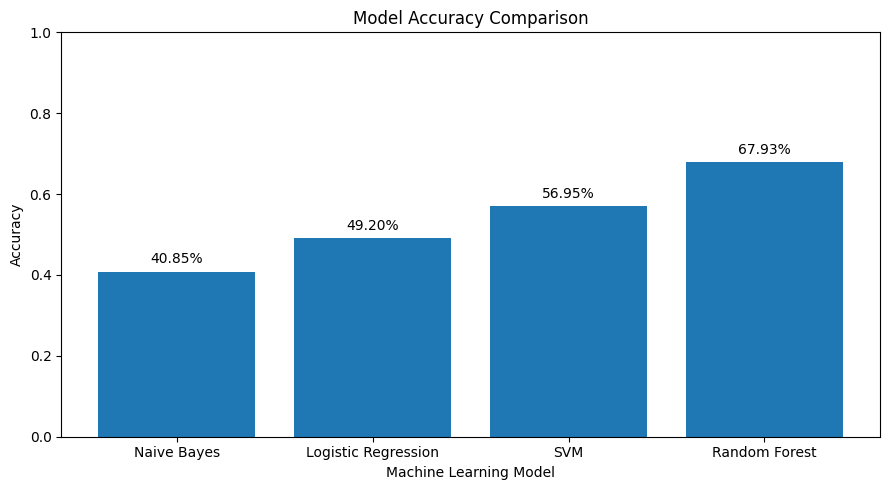

In [ ]:
model_names = [
    "Naive Bayes",
    "Logistic Regression",
    "SVM",
    "Random Forest"
]

model_accuracies = [
    nb_accuracy,
    lr_accuracy,
    svm_accuracy,
    rf_accuracy
]

plt.figure(figsize=(9, 5))

plt.bar(model_names, model_accuracies)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")

plt.ylim(0, 1)

for i, accuracy in enumerate(model_accuracies):
    plt.text(
        i,
        accuracy + 0.02,
        f"{accuracy * 100:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

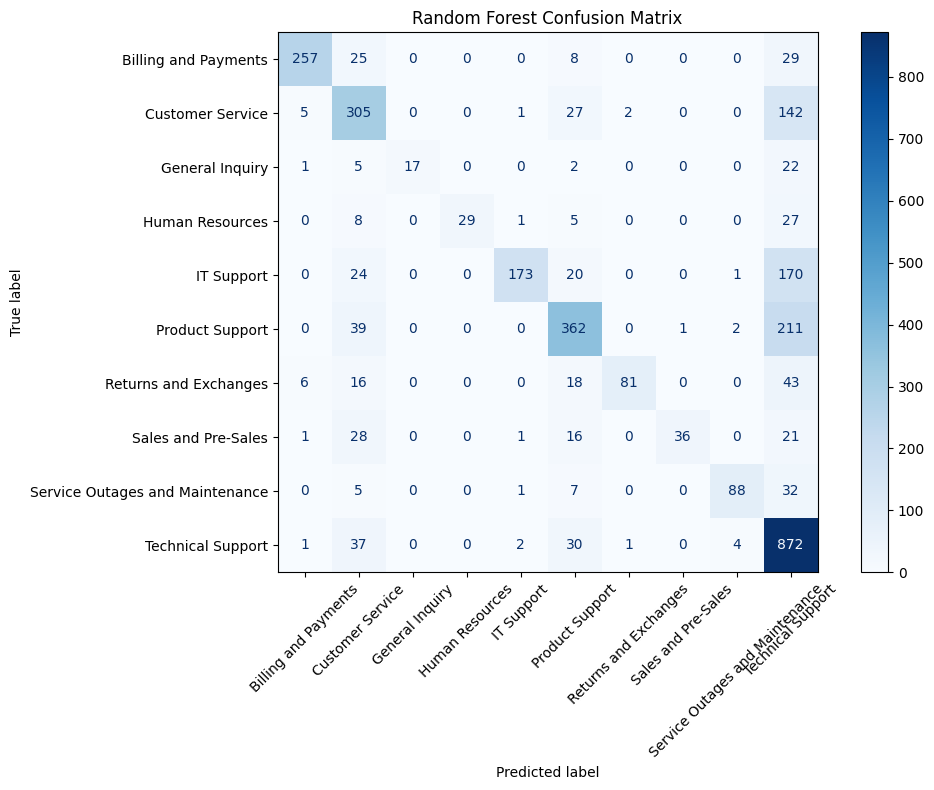

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(11, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_model.classes_
)

disp.plot(
    xticks_rotation=45,
    cmap="Blues",
    ax=plt.gca()
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

tokenizer = Tokenizer(
    num_words=10000,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

print("Vocabulary size:", len(tokenizer.word_index))
print("First training sequence:")
print(X_train_seq[0][:20])

Vocabulary size: 4160
First training sequence:
[25, 41, 389, 22, 2241, 10, 4, 86, 3483, 267, 60, 41, 71, 93, 118, 22, 51, 8, 141, 14]


In [ ]:
MAX_LEN = 60

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training padded shape:", X_train_pad.shape)
print("Testing padded shape:", X_test_pad.shape)

Training padded shape: (13070, 60)
Testing padded shape: (3268, 60)


In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_gru = label_encoder.fit_transform(y_train)
y_test_gru = label_encoder.transform(y_test)

print("Number of classes:", len(label_encoder.classes_))
print("\nQueue classes:")
for i, class_name in enumerate(label_encoder.classes_):
    print(i, "=", class_name)

Number of classes: 10

Queue classes:
0 = Billing and Payments
1 = Customer Service
2 = General Inquiry
3 = Human Resources
4 = IT Support
5 = Product Support
6 = Returns and Exchanges
7 = Sales and Pre-Sales
8 = Service Outages and Maintenance
9 = Technical Support


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Embedding,
    GRU,
    Dense,
    Dropout,
    Attention,
    GlobalAveragePooling1D
)

# Input layer
inputs = Input(shape=(MAX_LEN,))

# Embedding layer
embedding = Embedding(
    input_dim=10001,
    output_dim=128
)(inputs)

# GRU layer
gru_output = GRU(
    128,
    return_sequences=True
)(embedding)

# Attention layer
attention_output = Attention()(
    [gru_output, gru_output]
)

# Convert attention sequence into a single vector
context_vector = GlobalAveragePooling1D()(attention_output)

# Dense layer
dense = Dense(
    64,
    activation="relu"
)(context_vector)

# Dropout
dropout = Dropout(0.3)(dense)

# Output layer
outputs = Dense(
    10,
    activation="softmax"
)(dropout)

# Create model
gru_attention_model = Model(
    inputs=inputs,
    outputs=outputs
)

# Compile model
gru_attention_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("GRU + Attention model created successfully!")

gru_attention_model.summary()

GRU + Attention model created successfully!


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 60)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 60, 128)   │  1,280,128 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 60, 128)   │     99,072 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_1         │ (None, 60, 128)   │          0 │ gru_1[0][0],      │
│ (Attention)         │                   │            │ gru_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ attention_1[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      8,256 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 10)        │        650 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,388,106 (5.30 MB)

 Trainable params: 1,388,106 (5.30 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = gru_attention_model.fit(
    X_train_pad,
    y_train_gru,
    validation_split=0.1,
    epochs=5,
    batch_size=64,
    verbose=1
)

Epoch 1/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 40s 187ms/step - accuracy: 0.3025 - loss: 1.9429 - val_accuracy: 0.3611 - val_loss: 1.7417
Epoch 2/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 41s 188ms/step - accuracy: 0.3791 - loss: 1.7000 - val_accuracy: 0.4093 - val_loss: 1.6487
Epoch 3/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 44s 203ms/step - accuracy: 0.4115 - loss: 1.5795 - val_accuracy: 0.4109 - val_loss: 1.6336
Epoch 4/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 35s 188ms/step - accuracy: 0.4452 - loss: 1.4941 - val_accuracy: 0.4407 - val_loss: 1.5594
Epoch 5/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 38s 209ms/step - accuracy: 0.4896 - loss: 1.3901 - val_accuracy: 0.4269 - val_loss: 1.5673


In [ ]:
gru_test_loss, gru_test_accuracy = gru_attention_model.evaluate(
    X_test_pad,
    y_test_gru,
    verbose=1
)

print("GRU + Attention Test Accuracy:", gru_test_accuracy)
print("GRU + Attention Test Accuracy (%):", gru_test_accuracy * 100)

103/103 ━━━━━━━━━━━━━━━━━━━━ 6s 57ms/step - accuracy: 0.4360 - loss: 1.5813
GRU + Attention Test Accuracy: 0.4360465109348297
GRU + Attention Test Accuracy (%): 43.60465109348297


In [ ]:
from sklearn.metrics import classification_report

y_pred_gru_prob = gru_attention_model.predict(X_test_pad)
y_pred_gru = y_pred_gru_prob.argmax(axis=1)

print("GRU + Attention Classification Report:\n")

print(
    classification_report(
        y_test_gru,
        y_pred_gru,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step
GRU + Attention Classification Report:

                                 precision    recall  f1-score   support

           Billing and Payments       0.85      0.65      0.74       319
               Customer Service       0.35      0.41      0.38       482
                General Inquiry       0.00      0.00      0.00        47
                Human Resources       0.85      0.16      0.27        70
                     IT Support       0.33      0.35      0.34       388
                Product Support       0.39      0.29      0.33       615
          Returns and Exchanges       0.33      0.24      0.27       164
            Sales and Pre-Sales       0.54      0.07      0.12       103
Service Outages and Maintenance       0.63      0.57      0.60       133
              Technical Support       0.43      0.61      0.51       947

                       accuracy                           0.44      3268
                      macro avg       0.

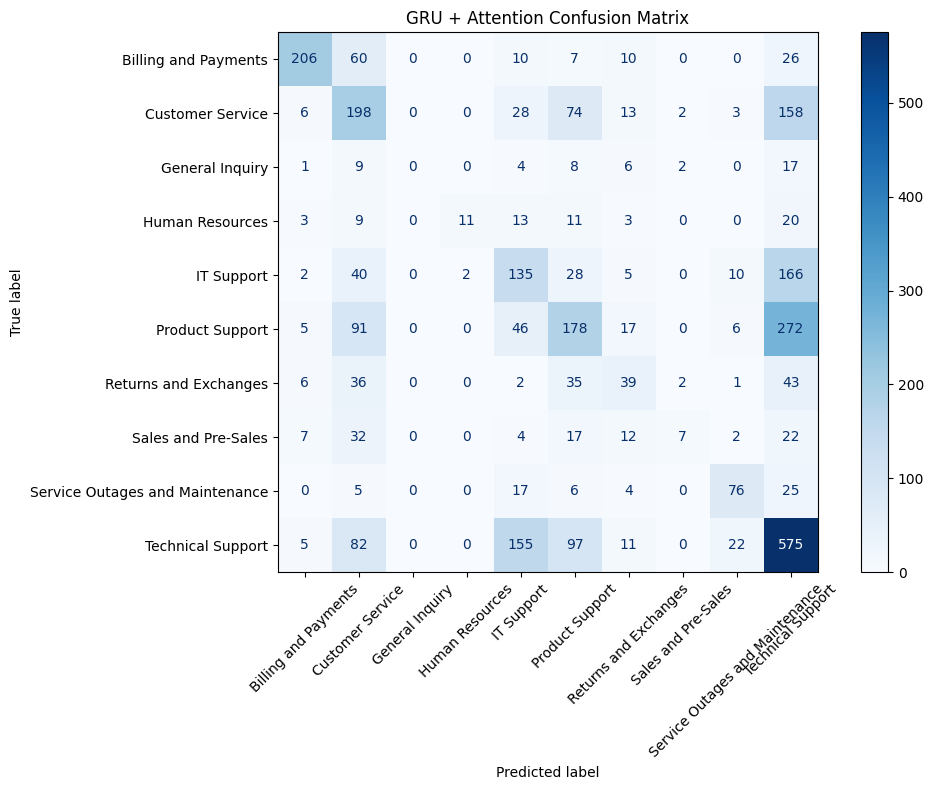

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_gru = confusion_matrix(y_test_gru, y_pred_gru)

plt.figure(figsize=(11, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_gru,
    display_labels=label_encoder.classes_
)

disp.plot(
    xticks_rotation=45,
    cmap="Blues",
    ax=plt.gca()
)

plt.title("GRU + Attention Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Create priority label encoder
priority_encoder = LabelEncoder()

y_train_priority = priority_encoder.fit_transform(
    df_en.loc[X_train.index, "priority"]
)

y_test_priority = priority_encoder.transform(
    df_en.loc[X_test.index, "priority"]
)

print("Priority classes:")
for i, class_name in enumerate(priority_encoder.classes_):
    print(i, "=", class_name)

print("\nTraining priority samples:", len(y_train_priority))
print("Testing priority samples:", len(y_test_priority))

Priority classes:
0 = high
1 = low
2 = medium

Training priority samples: 13070
Testing priority samples: 3268


In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Embedding,
    GRU,
    Dense,
    Dropout,
    Attention,
    GlobalAveragePooling1D
)

# Input layer
priority_inputs = Input(shape=(MAX_LEN,))

# Embedding layer
priority_embedding = Embedding(
    input_dim=10001,
    output_dim=128
)(priority_inputs)

# GRU layer
priority_gru = GRU(
    128,
    return_sequences=True
)(priority_embedding)

# Attention layer
priority_attention = Attention()(
    [priority_gru, priority_gru]
)

# Convert sequence into a single vector
priority_context = GlobalAveragePooling1D()(
    priority_attention
)

# Dense layer
priority_dense = Dense(
    64,
    activation="relu"
)(priority_context)

# Dropout
priority_dropout = Dropout(0.3)(
    priority_dense
)

# Output layer: 3 priority classes
priority_outputs = Dense(
    3,
    activation="softmax"
)(priority_dropout)

# Create model
priority_model = Model(
    inputs=priority_inputs,
    outputs=priority_outputs
)

# Compile model
priority_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("GRU + Attention Priority Model created successfully!")

priority_model.summary()

GRU + Attention Priority Model created successfully!


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 60)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 60, 128)   │  1,280,128 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_2 (GRU)         │ (None, 60, 128)   │     99,072 │ embedding_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_2         │ (None, 60, 128)   │          0 │ gru_2[0][0],      │
│ (Attention)         │                   │            │ gru_2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ attention_2[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      8,256 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 3)         │        195 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,387,651 (5.29 MB)

 Trainable params: 1,387,651 (5.29 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
priority_history = priority_model.fit(
    X_train_pad,
    y_train_priority,
    validation_split=0.1,
    epochs=5,
    batch_size=64,
    verbose=1
)

Epoch 1/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 41s 188ms/step - accuracy: 0.4360 - loss: 1.0462 - val_accuracy: 0.4981 - val_loss: 1.0045
Epoch 2/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 36s 194ms/step - accuracy: 0.5147 - loss: 0.9653 - val_accuracy: 0.4935 - val_loss: 0.9975
Epoch 3/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 37s 201ms/step - accuracy: 0.5796 - loss: 0.8816 - val_accuracy: 0.5042 - val_loss: 0.9891
Epoch 4/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 39s 191ms/step - accuracy: 0.6370 - loss: 0.8018 - val_accuracy: 0.5302 - val_loss: 0.9751
Epoch 5/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 42s 195ms/step - accuracy: 0.6617 - loss: 0.7465 - val_accuracy: 0.5471 - val_loss: 1.0035


103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.5600 - loss: 0.9854
Priority GRU + Attention Test Accuracy: 0.5599755048751831
Priority GRU + Attention Test Accuracy (%): 55.99755048751831


In [ ]:
from sklearn.metrics import classification_report

# Get priority probabilities
priority_pred_prob = priority_model.predict(X_test_pad)

# Convert probabilities to predicted class
priority_pred = priority_pred_prob.argmax(axis=1)

print("Priority GRU + Attention Classification Report:\n")

print(
    classification_report(
        y_test_priority,
        priority_pred,
        target_names=priority_encoder.classes_,
        zero_division=0
    )
)

103/103 ━━━━━━━━━━━━━━━━━━━━ 8s 67ms/step
Priority GRU + Attention Classification Report:

              precision    recall  f1-score   support

        high       0.56      0.73      0.63      1275
         low       0.61      0.31      0.41       690
      medium       0.55      0.52      0.54      1303

    accuracy                           0.56      3268
   macro avg       0.57      0.52      0.53      3268
weighted avg       0.57      0.56      0.55      3268



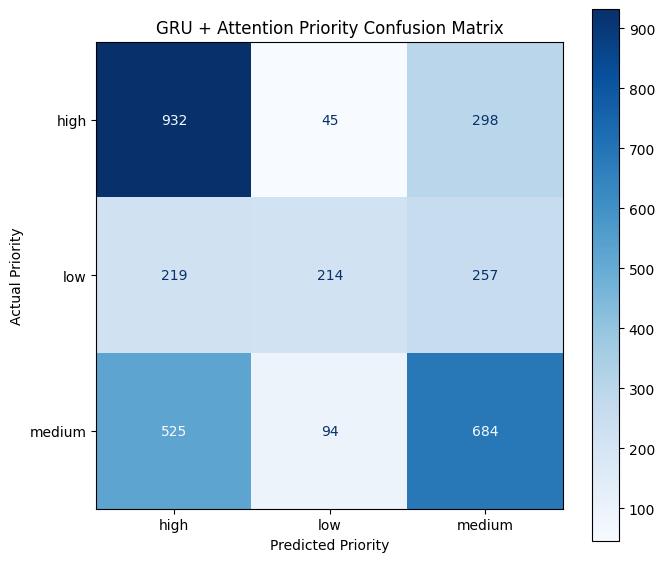

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_priority = confusion_matrix(
    y_test_priority,
    priority_pred
)

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_priority,
    display_labels=priority_encoder.classes_
)

disp.plot(
    cmap="Blues",
    ax=plt.gca()
)

plt.title("GRU + Attention Priority Confusion Matrix")
plt.xlabel("Predicted Priority")
plt.ylabel("Actual Priority")
plt.tight_layout()
plt.show()

In [ ]:
import os
import joblib

os.makedirs("project_models", exist_ok=True)

joblib.dump(tfidf, "project_models/tfidf_vectorizer.pkl")
joblib.dump(rf_model, "project_models/random_forest_model.pkl")

print("TF-IDF and Random Forest saved successfully!")

TF-IDF and Random Forest saved successfully!


In [ ]:
import joblib

# Save GRU routing model
gru_attention_model.save("project_models/gru_routing_model.keras")

# Save GRU priority model
priority_model.save("project_models/gru_priority_model.keras")

# Save tokenizer
joblib.dump(tokenizer, "project_models/tokenizer.pkl")

# Save queue label encoder
joblib.dump(label_encoder, "project_models/queue_label_encoder.pkl")

# Save priority label encoder
joblib.dump(priority_encoder, "project_models/priority_label_encoder.pkl")

print("All GRU models and supporting files saved successfully!")

All GRU models and supporting files saved successfully!


In [ ]:
import shutil

shutil.make_archive(
    "customer_support_models",
    "zip",
    "project_models"
)

print("Models ZIP created successfully!")

Models ZIP created successfully!


In [ ]:
from google.colab import files

files.download("customer_support_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>